# Bias audit of two credit-risk ADSs on a Databricks lakehouse

**Data:** [Home Credit – Credit Risk Model Stability](https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability) (Kaggle, 2024)
**Code:** https://github.com/GZ0012/home-credit-lakehouse-audit

## Goal

Two independently built automated decision systems (ADSs) predict whether a loan applicant will default:

| | System | Source |
|---|---|---|
| **A** | yuuniee, 1st place (CatBoost + LightGBM + DenseLight) | [Kaggle write-up](https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability/writeups/yuuniee-1st-place-solution-my-betting-strategy) |
| **B** | Evgeniia Volkova (LightGBM / CatBoost, time-window features) | [GitHub, commit `d5e228c`](https://github.com/evgeniavolkova/kagglehomecredit2024/tree/d5e228cdf7e9bf81d10805cff205b473a94c2063) |

We rebuild both pipelines on the same data and ask: **where along the pipeline does bias against groups of applicants enter?**
We use the three sources of bias from Friedman & Nissenbaum (1996):

| Bias type | Question for this project | Status |
|---|---|---|
| **Pre-existing** | Do default rates already differ by gender, age and family state in the raw data, before any modelling? | **Done** (section 3) |
| **Technical** | Do the design choices of each pipeline (fallbacks, aggregations, sampling, missing values) change how groups are represented or how well they are predicted? | Plan (section 4) |
| **Emergent** | Do the group gaps change over time (`WEEK_NUM`), i.e. once the model is used on later applicants? | Plan (section 5) |

## How to run this notebook on Databricks

1. In the Databricks workspace: **Workspace → Create → Git folder**, paste `https://github.com/GZ0012/home-credit-lakehouse-audit`, then open `notebooks/audit_report.ipynb`.
2. Attach any compute (serverless or a cluster, DBR 14+). `pyspark`, `pandas`, `scipy` and `matplotlib` come with the runtime.
3. The audit cells read three **bronze** tables from Unity Catalog. In our workspace they are in catalog `dbw_home_credit_audit`. In a new workspace, upload the Kaggle zip to the volume `<catalog>.bronze.raw_uploads`, run `notebooks/bronze/01–03`, and set `CATALOG` in the next cell.
4. **Run all** only runs the audit (section 3, about 1–3 minutes). The pipeline steps in section 2 are shown as simplified code; the full scripts are linked and run on their own.

Saved outputs in this notebook come from our Databricks run, so the results can be read on GitHub without running anything.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display as show
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from scipy.stats import chi2_contingency

spark = SparkSession.builder.getOrCreate()

CATALOG = "dbw_home_credit_audit"   # change for another workspace
BRONZE = f"{CATALOG}.bronze"
FIGURES = "../docs/figures"          # relative to this notebook in the Git folder

## 1. Architecture

All processing runs on Databricks (Delta Lake tables in Unity Catalog), in medallion layers. Raw Kaggle files go to **bronze** (one Delta table per Kaggle table). Each system then has its own **silver** layer (one feature table per data source, one row per case) and **gold** layer (all features joined, one row per case), followed by the same LightGBM training code. Our own audit work lives in separate `explore/` folders, so the replication code stays a faithful copy of what the authors did.

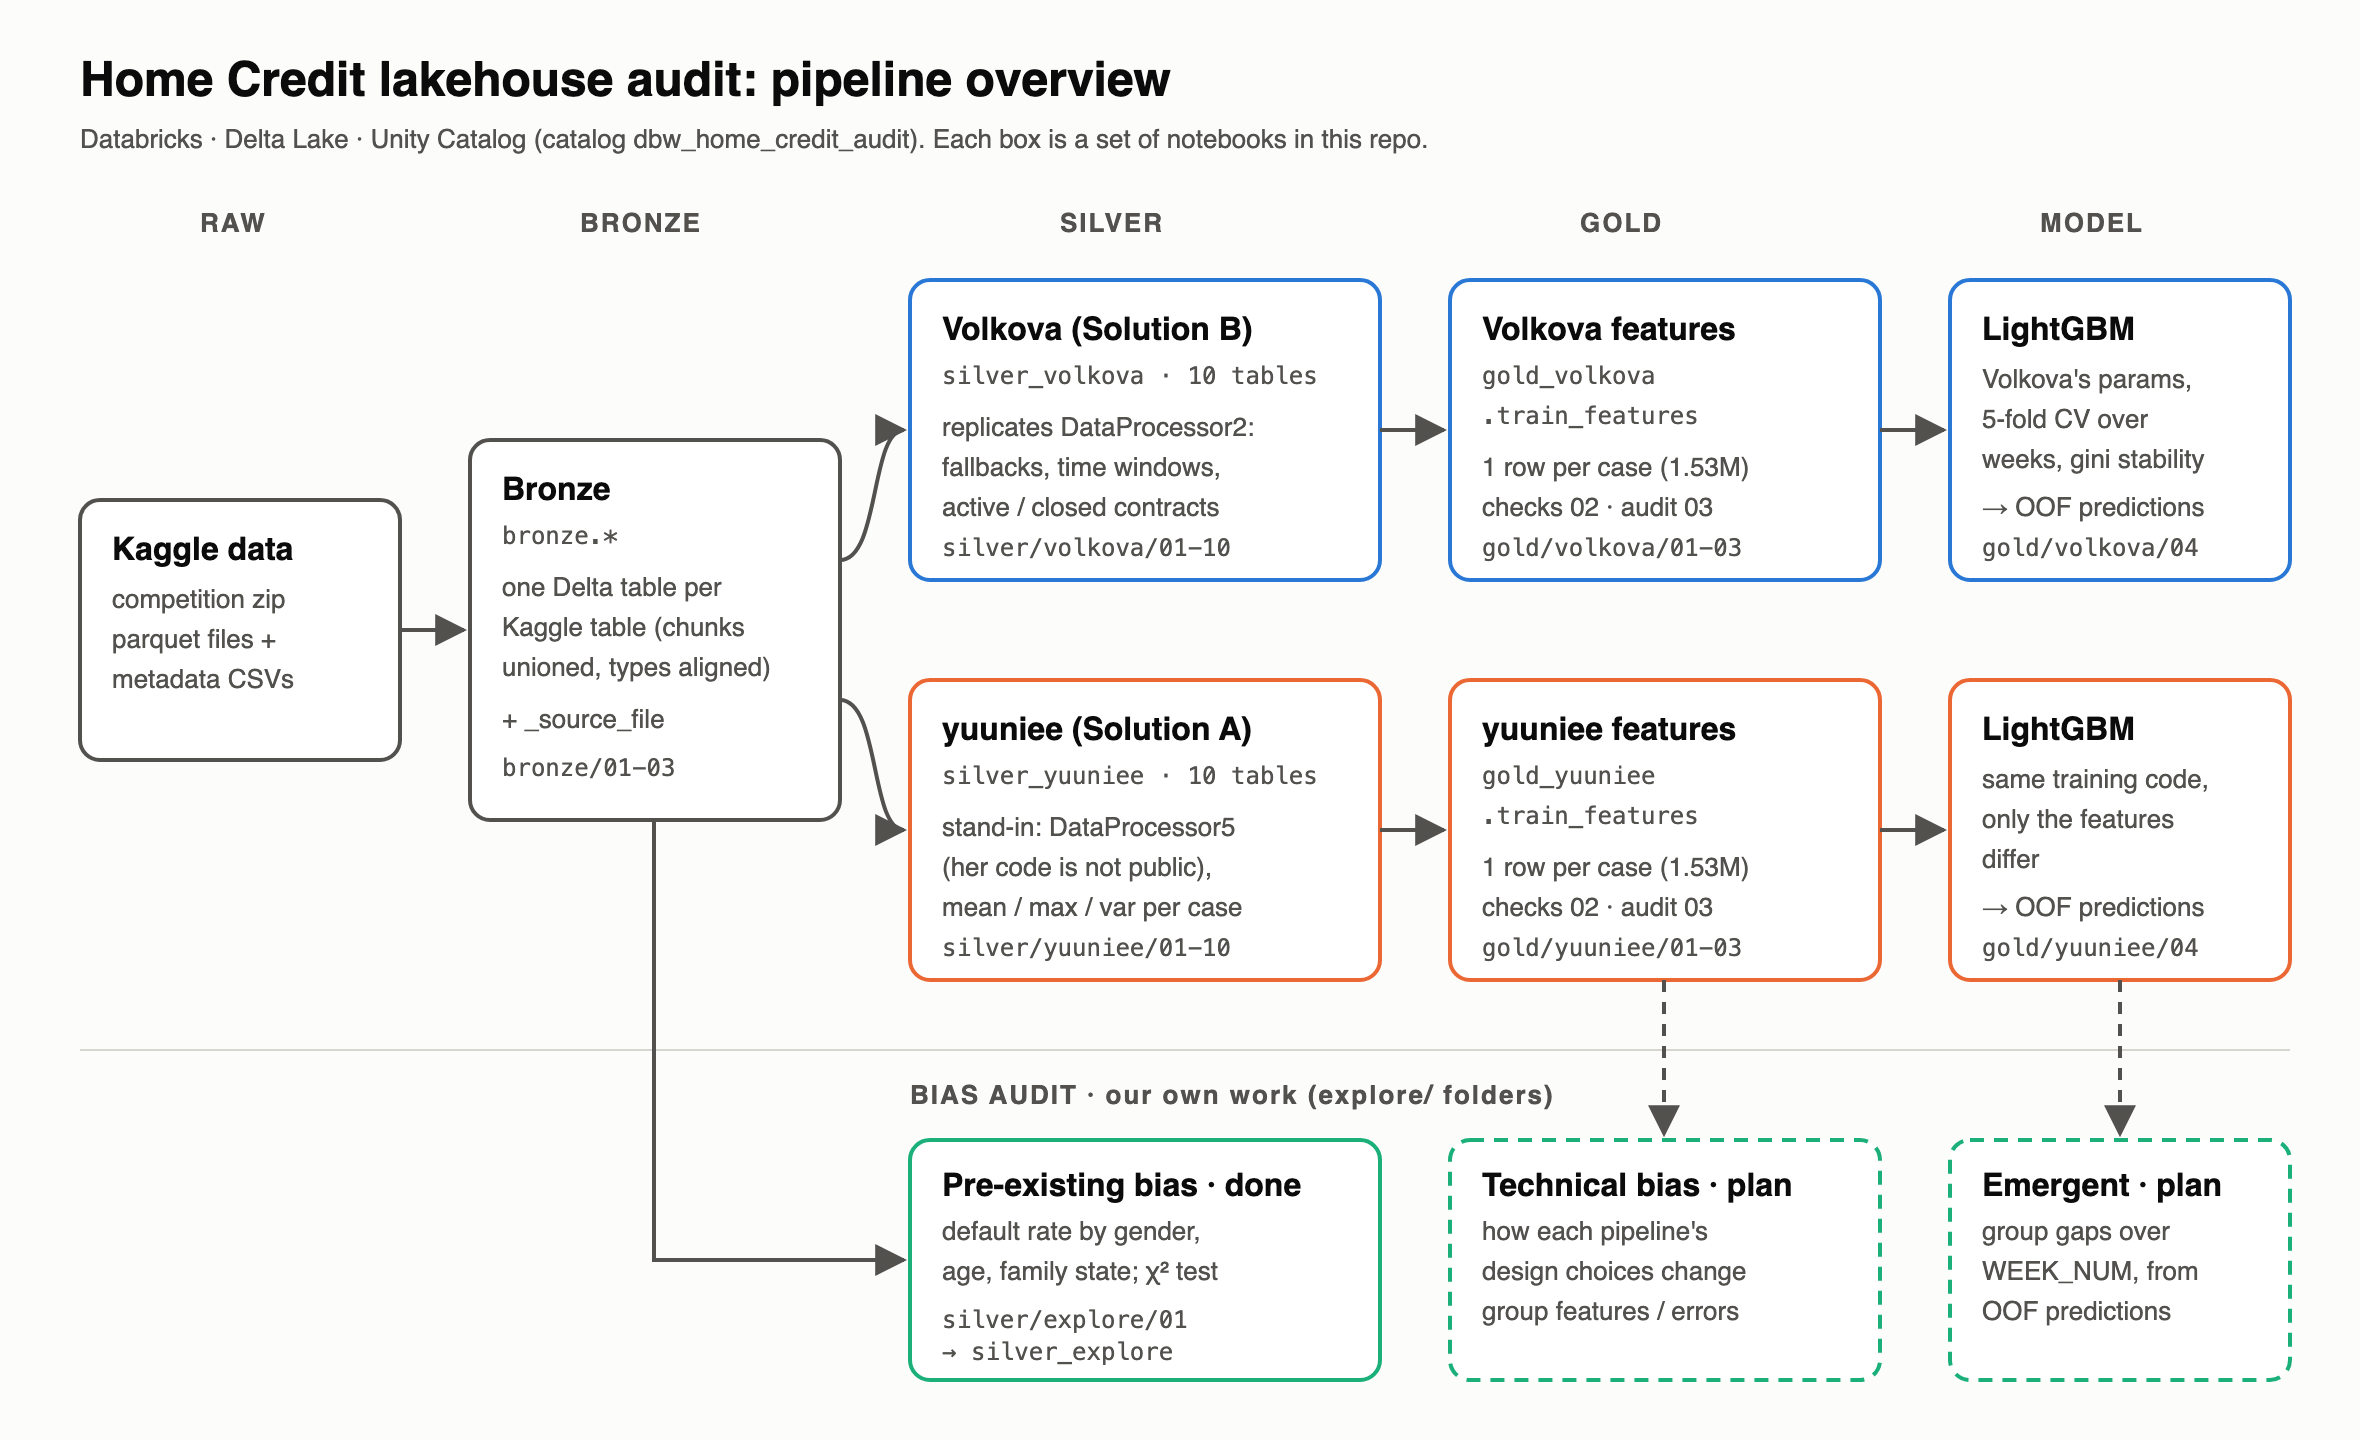

In [ ]:
show(Image(filename=f"{FIGURES}/pipeline_overview.png", width=1100))

**Feature lineage.** We built the feature engineering for **both systems**, using the same 10 silver steps. Each step reads its bronze tables and writes one silver table per system (`silver_volkova.*` for B, `silver_yuuniee.*` for A). The letters B and A in the figure show how each system processes that source. Each system's 10 silver tables are then joined into its own gold training table. The scripts for every step are linked in section 2.2.

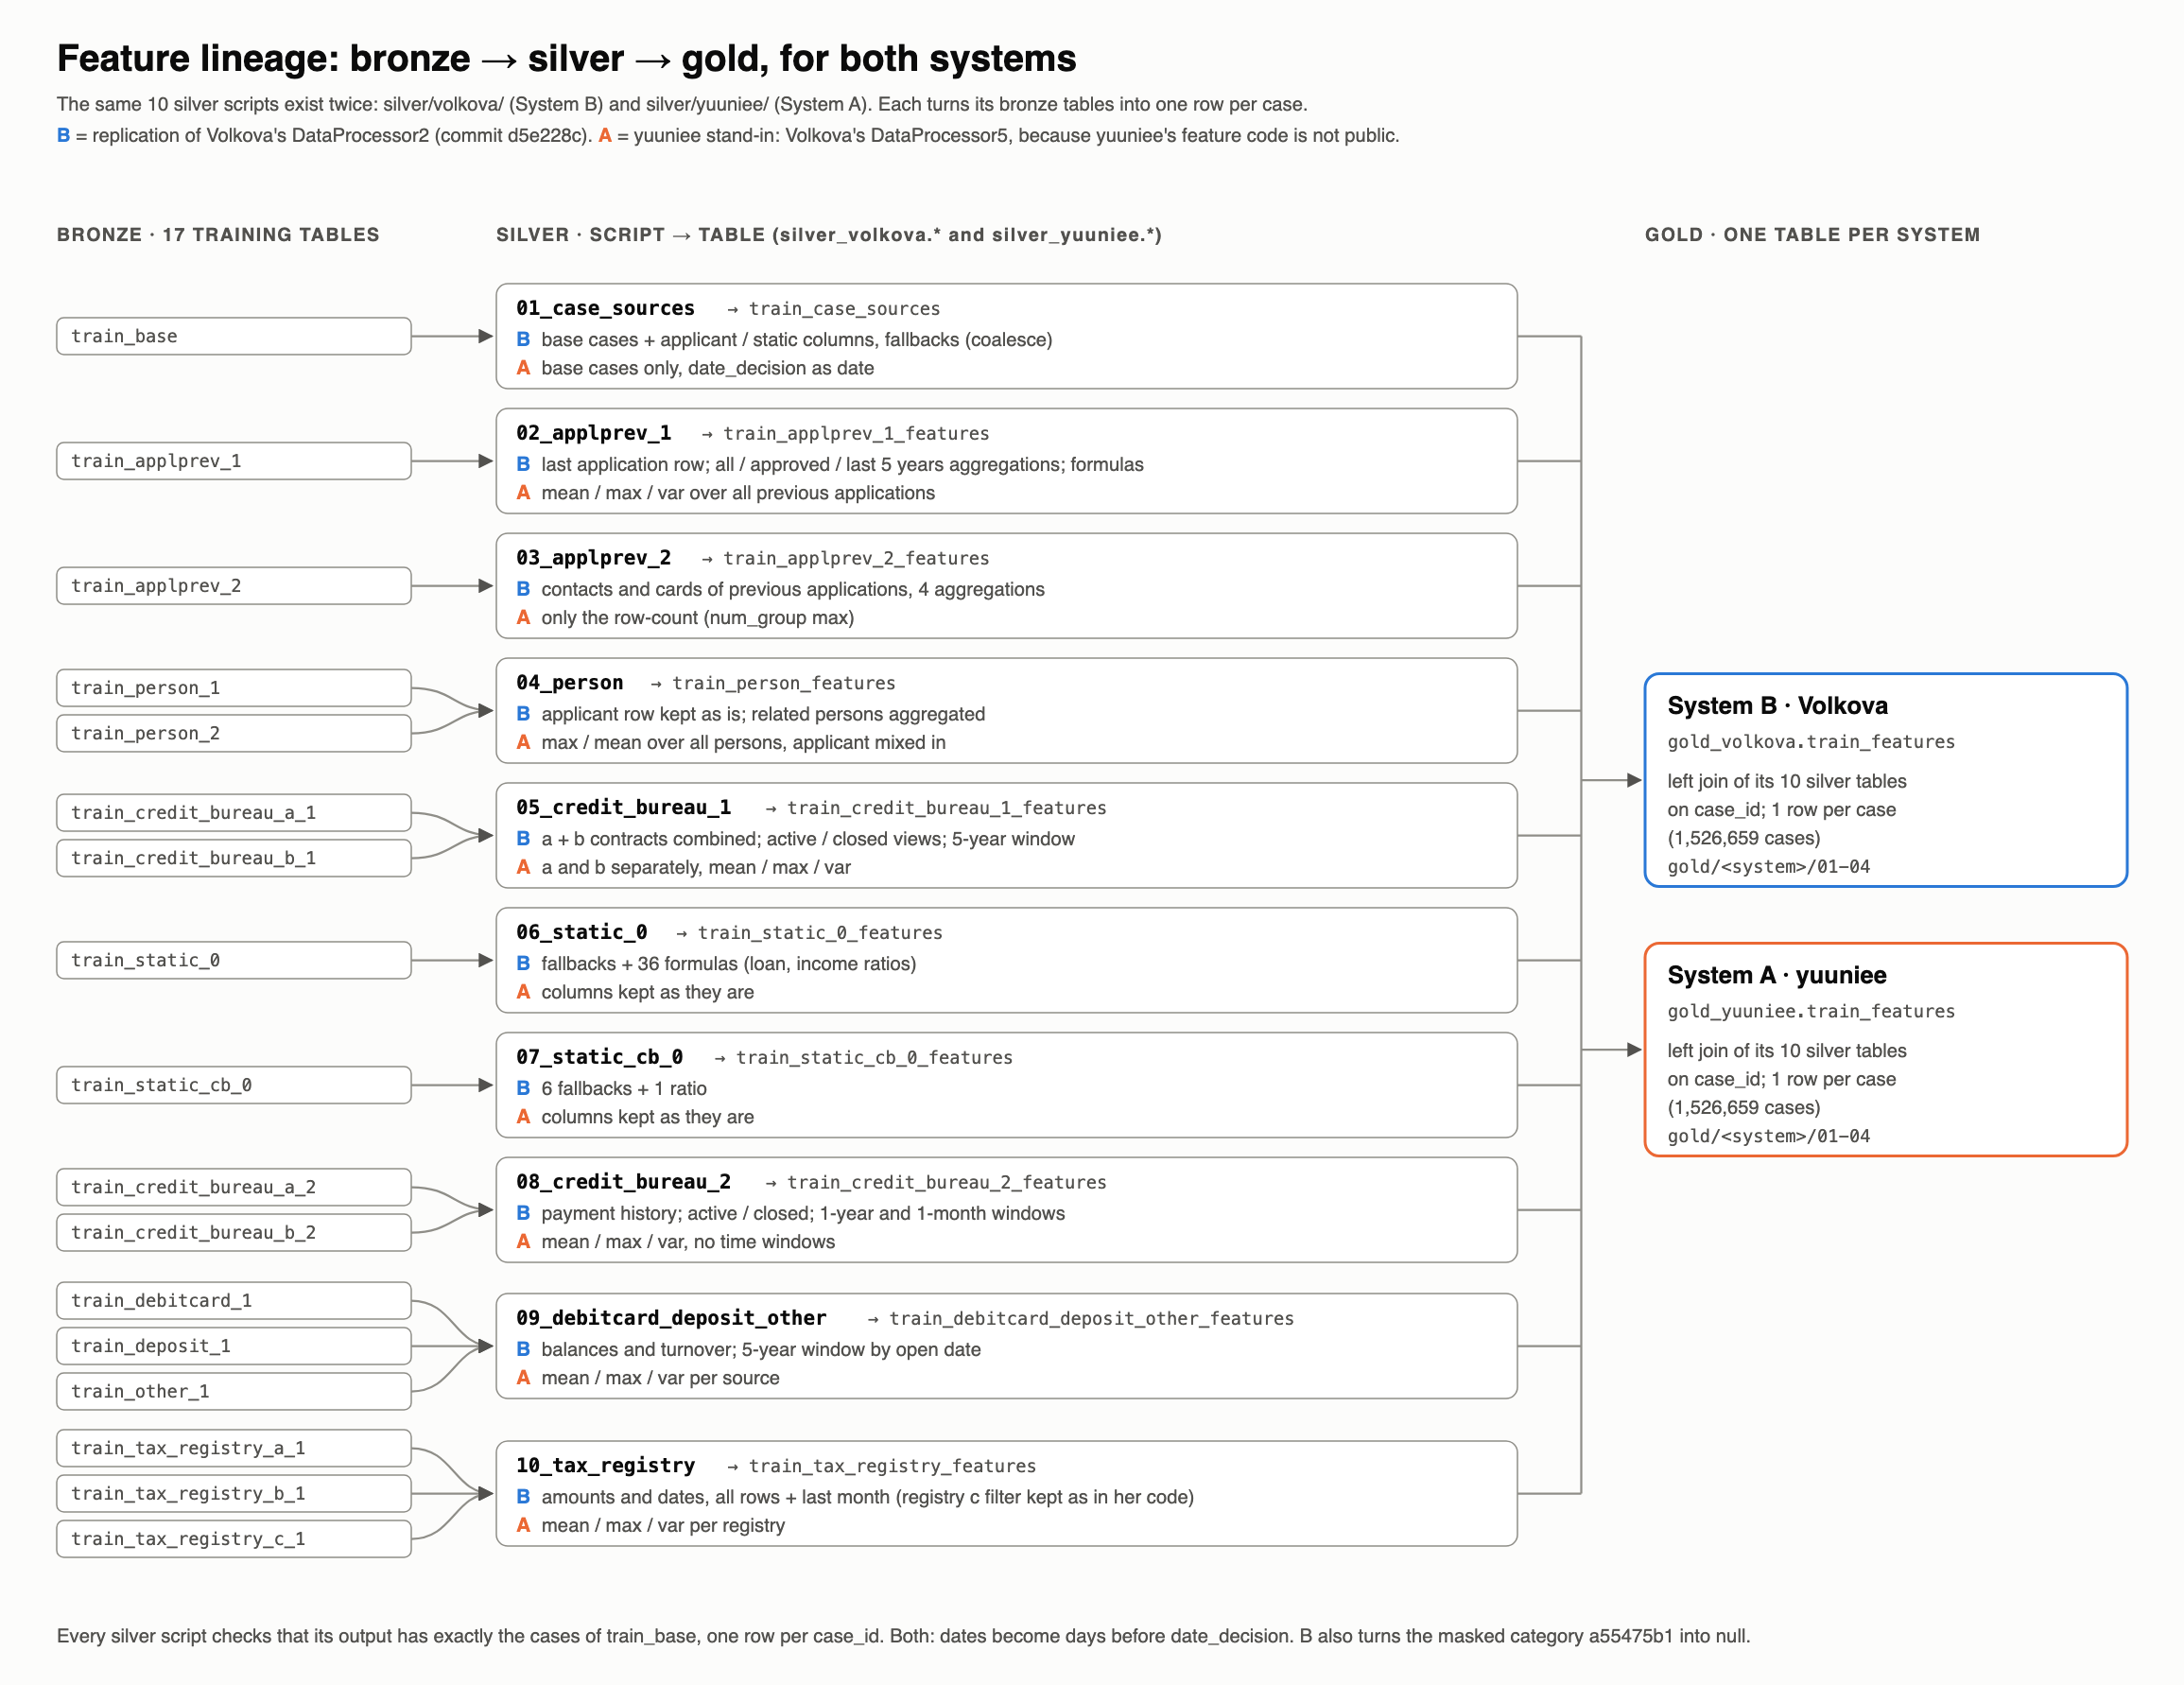

In [ ]:
show(Image(filename=f"{FIGURES}/feature_lineage.png", width=1100))

## 2. What we built, step by step

Each step below says what the step does, shows a **simplified** version of the code, and links the full script. The simplified code is for reading only; the full scripts are the ones we ran.

### 2.1 Bronze: raw files → Delta tables

[`notebooks/bronze/01–03`](https://github.com/GZ0012/home-credit-lakehouse-audit/tree/main/notebooks/bronze)

- **01–02:** stream the metadata CSVs and every parquet file out of the competition zip into a Unity Catalog volume, 8 MB at a time. Writes go to a `.partial` file first, so a failed run can be restarted safely.
- **03:** Kaggle splits large tables into numbered chunks (`train_credit_bureau_a_2_0 … _10`). Each group of chunks becomes one Delta table. Chunks do not always share column types (a column can be all-null in one chunk, `int` in one and `double` in another), so types are aligned before the union. Every row keeps `_source_file` for lineage, and the row count is checked against the parquet footers.

```python
for table, files in group_parquet_files().items():          # train_static_0_0, _1 -> train_static_0
    parts = [spark.read.parquet(f).withColumn("_source_file", F.col("_metadata.file_name")) for f in files]
    types = resolve_types(parts)                              # void -> string, int + double -> double
    df = union_by_name([cast_columns(p, types) for p in parts]).withColumn("_ingested_at", F.current_timestamp())
    df.write.mode("overwrite").saveAsTable(f"{CATALOG}.bronze.{table}")
    assert spark.table(f"{CATALOG}.bronze.{table}").count() == footer_row_count(files)
```

Before building silver we profiled the bronze data: `case_id` is unique in `train_base` (1,526,659 labelled cases) and we measured the null rate of every column in every table ([`silver/01_data_finding.py`, `silver/02_data_check.py`](https://github.com/GZ0012/home-credit-lakehouse-audit/tree/main/notebooks/silver)).

### 2.2 Silver: one feature table per source, one row per case

Kaggle's tables are at different depths: depth 0 has one row per case, depth 1 and 2 have many rows per case (previous applications, credit-bureau contracts, monthly payments …). Silver brings every source down to **one row per `case_id`**. We wrote 10 scripts per system, one per source group, and each one checks that the output has exactly the cases of `train_base`.

**Feature engineering in our repository.** Each row links the script we wrote for that step, once for each system:

| Step | Bronze input | System B (Volkova replication) | System A (yuuniee stand-in) |
|---|---|---|---|
| 01 | `train_base` | [01_case_sources.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/01_case_sources.py): base cases + applicant / static columns with fallbacks | [01_case_sources.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/01_case_sources.py): base cases only |
| 02 | `train_applprev_1` | [02_applprev_1.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/02_applprev_1.py): last application; all / approved / 5-year aggregations; formulas | [02_applprev_1.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/02_applprev_1.py): mean / max / var |
| 03 | `train_applprev_2` | [03_applprev_2.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/03_applprev_2.py): contacts and cards, 4 aggregations | [03_applprev_2.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/03_applprev_2.py): row count only |
| 04 | `train_person_1, train_person_2` | [04_person.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/04_person.py): applicant row kept; related persons aggregated | [04_person.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/04_person.py): aggregated over all persons |
| 05 | `train_credit_bureau_a_1, _b_1` | [05_credit_bureau_1.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/05_credit_bureau_1.py): a + b combined; active / closed views; 5-year window | [05_credit_bureau_1.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/05_credit_bureau_1.py): mean / max / var |
| 06 | `train_static_0` | [06_static_0.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/06_static_0.py): fallbacks + 36 formulas | [06_static_0.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/06_static_0.py): columns as they are |
| 07 | `train_static_cb_0` | [07_static_cb_0.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/07_static_cb_0.py): 6 fallbacks + 1 ratio | [07_static_cb_0.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/07_static_cb_0.py): columns as they are |
| 08 | `train_credit_bureau_a_2, _b_2` | [08_credit_bureau_2.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/08_credit_bureau_2.py): payment history; active / closed; 1-year and 1-month windows | [08_credit_bureau_2.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/08_credit_bureau_2.py): mean / max / var |
| 09 | `train_debitcard_1, train_deposit_1, train_other_1` | [09_debitcard_deposit_other.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/09_debitcard_deposit_other.py): balances and turnover; 5-year window | [09_debitcard_deposit_other.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/09_debitcard_deposit_other.py): mean / max / var |
| 10 | `train_tax_registry_a_1, _b_1, _c_1` | [10_tax_registry.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/10_tax_registry.py): amounts and dates; all rows + last month | [10_tax_registry.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/yuuniee/10_tax_registry.py): mean / max / var |
| gold | all 10 silver tables | [gold/volkova/01_train_features.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/gold/volkova/01_train_features.py): join + combined tax features | [gold/yuuniee/01_train_features.py](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/gold/yuuniee/01_train_features.py): join + date parts |

Column-by-column documentation of System B's features (aggregations, fallbacks and the reason for each): [`silver/volkova/FEATURES.md`](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/FEATURES.md). The author code we follow: [Volkova `DataProcessor2`](https://github.com/evgeniavolkova/kagglehomecredit2024/blob/d5e228cdf7e9bf81d10805cff205b473a94c2063/homecredit/data/data_processor_2.py) for B and [`DataProcessor5`](https://github.com/evgeniavolkova/kagglehomecredit2024/blob/d5e228cdf7e9bf81d10805cff205b473a94c2063/homecredit/data/data_processor_5.py) for A.

**System B (Volkova): faithful replication** of her `DataProcessor2` — [`silver/volkova/01–10`](https://github.com/GZ0012/home-credit-lakehouse-audit/tree/main/notebooks/silver/volkova), documented column by column in [`FEATURES.md`](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/volkova/FEATURES.md):

- dates become days before `date_decision`, and the masked category `a55475b1` becomes null;
- **fallbacks**: one attribute is often stored in several columns, so she takes the first non-null one (e.g. gender = `gender_992L`, else `sex_738L`);
- the **applicant** (`num_group1 = 0`) is kept as one row; related persons are aggregated;
- time windows (last 30 days, last year …) and active / closed views of bureau contracts;
- two bugs in her code are kept on purpose (switchable flags), because the audit is about the system as it was built: the "closed" contract view filters on *active* rows, and one tax-registry filter uses the amount instead of the date.

```python
rows = clean(spark.table("bronze.train_person_1"))            # dates -> days, a55475b1 -> null
rows = rows.withColumn("gender_992L", F.coalesce("gender_992L", "sex_738L"))   # her fallback
applicant = rows.where("num_group1 = 0")                       # applicant kept as one row
related = (rows.where("num_group1 != 0").groupBy("case_id")
               .agg(*[agg(col, op) for col, op in FEATURES_2_CSV]))  # min / max / mode / nunique
```

**System A (yuuniee): stand-in.** yuuniee's feature code is not public. We use Volkova's simpler `DataProcessor5` instead: per source, mean / max / variance of the columns listed in her `features5.txt`, no hand-made features, no fallbacks — [`silver/yuuniee/01–10`](https://github.com/GZ0012/home-credit-lakehouse-audit/tree/main/notebooks/silver/yuuniee). One consequence matters for fairness: person attributes are aggregated over **all** persons of a case (applicant and related persons together), so a column such as `sex_738L_1_max` is not the applicant's own gender.

```python
rows = clean(spark.table("bronze.train_person_1"))
features = rows.groupBy("case_id").agg(
    *[F.avg(c), F.max(c), F.var_samp(c) for c in FEATURES_5]   # applicant mixed with related persons
)
```

### 2.3 Gold: one training table per system

[`gold/volkova/01–03`](https://github.com/GZ0012/home-credit-lakehouse-audit/tree/main/notebooks/gold/volkova), [`gold/yuuniee/01–03`](https://github.com/GZ0012/home-credit-lakehouse-audit/tree/main/notebooks/gold/yuuniee)

- **01** left-joins the 9 silver feature tables onto the case table and runs her final step (±inf → null; combined tax features for B, date parts for A). Result: `gold_<system>.train_features`, one row per case.
- **02 checks:** same cases as silver, `target` / `WEEK_NUM` unchanged, no inf/NaN left, and a 1 % sample of cases matches the silver tables.
- **03 audit:** for random cases we recompute features **straight from bronze**, without the silver code, and compare them with gold. We also flag single features with an AUC far from 0.5 (possible leaks), and drift (PSI) between early and late weeks.

```python
features = spark.table(f"silver_{system}.train_case_sources").select("case_id", "date_decision", "WEEK_NUM", "target")
for table in SILVER_TABLES:
    features = features.join(spark.table(f"silver_{system}.{table}"), "case_id", "left")
features = final_processor(features)           # inf -> null, combined / date features
features.write.saveAsTable(f"gold_{system}.train_features")
```

### 2.4 Model: same LightGBM for both systems

[`gold/volkova/04_train_lgbm.py`](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/gold/volkova/04_train_lgbm.py), [`gold/yuuniee/04_train_lgbm.py`](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/gold/yuuniee/04_train_lgbm.py)

Both systems are trained with Volkova's LightGBM parameters and cross-validation (5 folds over whole weeks, no shuffling; early stopping on a 1 % hold-out; metric: the competition's gini stability). The training code is the same for both, so **only the features differ** — any difference between the two models comes from the feature pipelines. To fit in driver memory we train on a 30 % sample of cases and run the last fold (latest weeks as validation). Outputs: per-fold metrics, weekly gini, feature importance and out-of-fold predictions, which the technical and emergent audits will use.

```python
weeks = sorted(df["WEEK_NUM"].unique())
for fold, (train_w, valid_w) in enumerate(KFold(5, shuffle=False).split(weeks)):
    model = lgb.LGBMClassifier(**params_lgb).fit(X_train, y_train, eval_set=[(X_hold, y_hold)],
                                                 callbacks=[lgb.early_stopping(200)])
    oof[valid_rows] = model.predict_proba(X_valid)[:, 1]
```

## 3. Pre-existing bias (done)

**Question:** before any feature engineering or model, does the default rate (`target = 1`) differ between groups of applicants?

This is measured on **bronze only** ([`silver/explore/01_pre_existing_bias.py`](https://github.com/GZ0012/home-credit-lakehouse-audit/blob/main/notebooks/silver/explore/01_pre_existing_bias.py)). Both systems use the same cases and labels (`train_base`, unchanged), so the result holds for both.

**Groups** (always the applicant, i.e. the `train_person_1` row with `num_group1 = 0`):

| Attribute | Built from | Notes |
|---|---|---|
| gender | `gender_992L`, else `sex_738L` | |
| age | birth date from `train_static_cb_0` (`birthdate_574D` → `dateofbirth_337D` → `dateofbirth_342D`), else `train_person_1` (`birth_259D` → `birthdate_87D`); age at `date_decision` | bins <18, 18–24, …, 65+ |
| family state | `familystate_447L` | `maritalst_385M` is not used: its values are hashed codes |

The masked category `a55475b1` and nulls form their own `missing` group.

**Metrics per group:** number of cases, defaults and repayments, default rate, gap to the overall rate and to a reference group (the largest non-missing group), and ratios in both directions (default-rate ratio, and repaid-rate ratio as used by the four-fifths rule). A χ² test checks whether `target` is independent of the group, with and without the `missing` group. Weekly rates show whether the gaps are stable over time.

In [ ]:
MISSING_CATEGORY = "a55475b1"          
AGE_BINS = [18, 25, 35, 45, 55, 65]    
ATTRIBUTES = ["gender", "age_group", "family_state"]


def category(column):
    value = F.col(column).cast("string")
    return F.when(value != MISSING_CATEGORY, value)


def first_date(*columns):
    return F.coalesce(*[F.col(c).cast("date") for c in columns])


cases = spark.table(f"{BRONZE}.train_base").select(
    "case_id", "WEEK_NUM", "target", F.col("date_decision").cast("date").alias("date_decision"))
applicant = (
    spark.table(f"{BRONZE}.train_person_1").where(F.col("num_group1") == 0)
    .select("case_id",
            F.coalesce(category("gender_992L"), category("sex_738L")).alias("gender_value"),
            category("familystate_447L").alias("family_value"),
            first_date("birth_259D", "birthdate_87D").alias("person_birthdate"))
)
external = spark.table(f"{BRONZE}.train_static_cb_0").select(
    "case_id", first_date("birthdate_574D", "dateofbirth_337D", "dateofbirth_342D").alias("external_birthdate"))

people = (cases.join(applicant, "case_id", "left").join(external, "case_id", "left")
          .withColumn("birth_days", F.datediff(F.coalesce("external_birthdate", "person_birthdate"),
                                               F.col("date_decision"))))   # negative: days before decision

age = -F.col("birth_days") / 365.25

age_group = F.when(F.col("birth_days").isNull(), "missing").when(age < AGE_BINS[0], f"<{AGE_BINS[0]}")
for low, high in zip(AGE_BINS, AGE_BINS[1:]):
    age_group = age_group.when(age < high, f"{low}-{high - 1}")
age_group = age_group.otherwise(f"{AGE_BINS[-1]}+")

df = people.select(
    "case_id", "WEEK_NUM", "target",
    F.coalesce("gender_value", F.lit("missing")).alias("gender"),
    age_group.alias("age_group"),
    F.coalesce("family_value", F.lit("missing")).alias("family_state"),
    age.alias("age_years"),
).cache()

total = df.count()


if total != cases.count() or df.select("case_id").distinct().count() != total:
    raise ValueError("expected exactly one row per case after the joins")
overall_rate = df.agg(F.avg("target")).first()[0]
print(f"{total:,} cases, overall default rate {overall_rate:.4f}")

1,526,659 cases, overall default rate 0.0314


In [ ]:
def group_table(attribute):
    counts = (df.groupBy(F.col(attribute).alias("group"))
              .agg(F.count("*").alias("cases"), F.sum("target").alias("target_1"),
                   F.sum(1 - F.col("target")).alias("target_0"))
              .toPandas())
    
    counts.insert(0, "attribute", attribute)
    counts["share_of_cases"] = counts["cases"] / total
    counts["default_rate"] = counts["target_1"] / counts["cases"]
    counts["diff_vs_overall"] = counts["default_rate"] - overall_rate
    known = counts[counts["group"] != "missing"]
    
    reference = known.loc[known["cases"].idxmax()]
    
    
    counts["reference_group"] = reference["group"]
    counts["diff_vs_reference"] = counts["default_rate"] - reference["default_rate"]
    counts["default_ratio_vs_reference"] = counts["default_rate"] / reference["default_rate"]
   
   
    counts["repaid_ratio_vs_reference"] = (1 - counts["default_rate"]) / (1 - reference["default_rate"])
    return counts.sort_values("cases", ascending=False)


groups = pd.concat([group_table(a) for a in ATTRIBUTES], ignore_index=True)
short = {"target_1": "defaults", "share_of_cases": "share", "default_rate": "rate",
         "diff_vs_overall": "vs_overall", "default_ratio_vs_reference": "ratio_ref",
         "repaid_ratio_vs_reference": "repaid_ratio_ref"}
print(groups[["attribute", "group", "cases", *short]].rename(columns=short).round(4).to_string(index=False))

   attribute               group  cases  defaults  share   rate  vs_overall  ratio_ref  repaid_ratio_ref
      gender                   F 952776     25214 0.6241 0.0265     -0.0050     1.0000            1.0000
      gender                   M 573883     22780 0.3759 0.0397      0.0083     1.5000            0.9864
   age_group               25-34 377158     14767 0.2470 0.0392      0.0077     1.0000            1.0000
   age_group               35-44 365966     11917 0.2397 0.0326      0.0011     0.8317            1.0069
   age_group               45-54 278287      7864 0.1823 0.0283     -0.0032     0.7217            1.0113
   age_group               55-64 255165      4978 0.1671 0.0195     -0.0119     0.4983            1.0204
   age_group                 65+ 154560      2991 0.1012 0.0194     -0.0121     0.4943            1.0206
   age_group               18-24  95489      5474 0.0625 0.0573      0.0259     1.4641            0.9811
   age_group                 <18     34         3 0.000

In [ ]:
tests = []
for attribute in ATTRIBUTES:
    for include_missing in [True, False]:
        part = groups[groups["attribute"] == attribute]
        if not include_missing:
            part = part[part["group"] != "missing"]
        if len(part) < 2:
            continue
        chi2, p_value, dof, _ = chi2_contingency(part[["target_1", "target_0"]].values)
        rates = part["default_rate"]
        tests.append({"attribute": attribute, "include_missing": include_missing, "groups": len(part),
                      "chi2": chi2, "dof": dof, "p_value": p_value,
                      "cramers_v": (chi2 / part["cases"].sum()) ** 0.5,   # effect size for a 2 x k table
                      "min_rate": rates.min(), "max_rate": rates.max(),
                      "max_over_min": rates.max() / rates.min()})
tests = pd.DataFrame(tests)
print(tests.round(4).to_string(index=False))

   attribute  include_missing  groups      chi2  dof  p_value  cramers_v  min_rate  max_rate  max_over_min
      gender             True       2 2058.6318    1      0.0     0.0367    0.0265    0.0397        1.5000
      gender            False       2 2058.6318    1      0.0     0.0367    0.0265    0.0397        1.5000
   age_group             True       7 4884.2694    6      0.0     0.0566    0.0194    0.0882        4.5596
   age_group            False       7 4884.2694    6      0.0     0.0566    0.0194    0.0882        4.5596
family_state             True       6  791.0087    5      0.0     0.0228    0.0287    0.0558        1.9448
family_state            False       5  620.7957    4      0.0     0.0292    0.0287    0.0558        1.9448


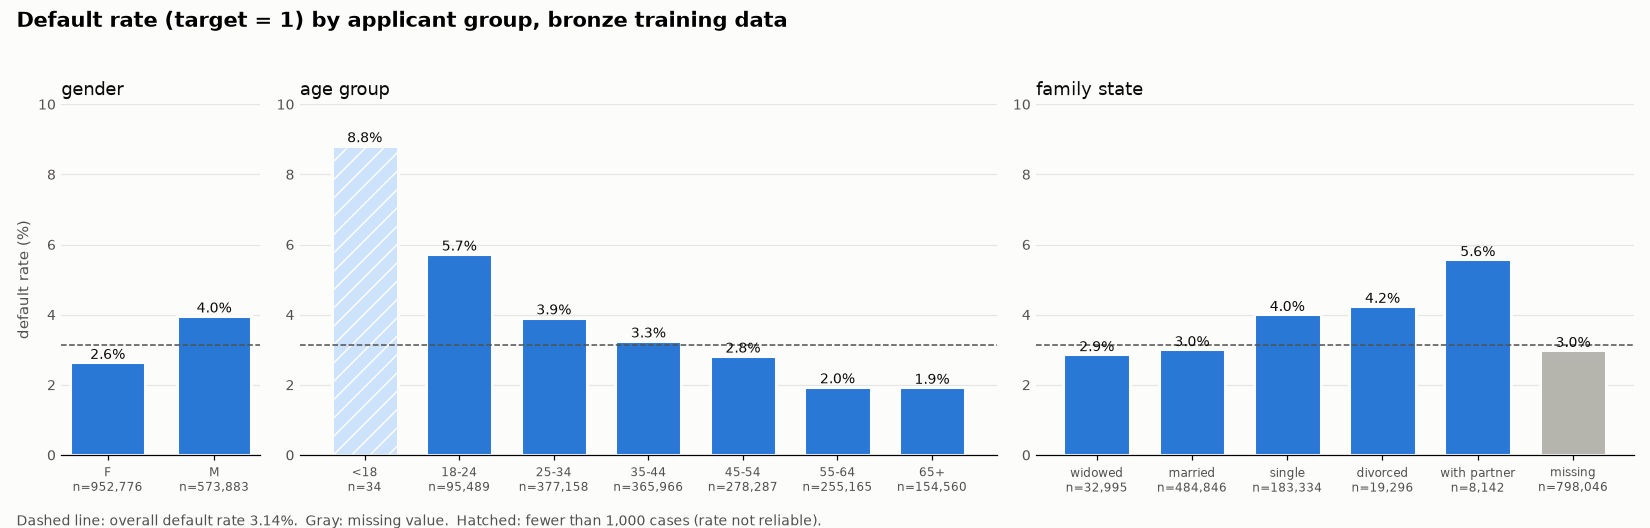

In [ ]:
import matplotlib.pyplot as plt

AGE_ORDER = ["<18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+", "missing"]
SMALL_GROUP = 1_000   # groups with fewer cases are drawn hatched: their rate is noise

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2, 7, 6]})
fig.patch.set_facecolor("#fcfcfb")
for ax, attribute in zip(axes, ATTRIBUTES):
    part = groups[groups["attribute"] == attribute].copy()
    if attribute == "age_group":
        part["order"] = part["group"].map({g: i for i, g in enumerate(AGE_ORDER)})
        part = part.sort_values("order")
    else:
        part["order"] = part["default_rate"] + (part["group"] == "missing")   # missing goes last
        part = part.sort_values("order")
    small = part["cases"] < SMALL_GROUP
    missing = part["group"] == "missing"
    ax.set_facecolor("#fcfcfb")
    bars = ax.bar(
        range(len(part)), part["default_rate"] * 100, width=0.7,
        color=["#b5b4ad" if m else "#cde2fb" if s else "#2a78d6" for s, m in zip(small, missing)],
        hatch=["//" if s else "" for s in small], edgecolor="#fcfcfb", linewidth=2,
    )
    ax.axhline(overall_rate * 100, color="#52514e", linestyle="--", linewidth=1)
    for bar, rate, n in zip(bars, part["default_rate"], part["cases"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{rate:.1%}",
                ha="center", va="bottom", fontsize=9, color="#0b0b0b")
    ax.set_xticks(range(len(part)))
    names = list(part["group"])
    if attribute == "family_state":
        names = [g.lower().replace("living_with_partner", "with partner") for g in names]
    ax.set_xticklabels([f"{g}\nn={n:,}" for g, n in zip(names, part["cases"])], fontsize=8, color="#52514e")
    ax.set_title(attribute.replace("_", " "), loc="left", fontsize=12, color="#0b0b0b")
    ax.set_ylim(0, 10)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", colors="#52514e", length=0, labelsize=9)
axes[0].set_ylabel("default rate (%)", color="#52514e")
fig.suptitle("Default rate (target = 1) by applicant group, bronze training data",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, f"Dashed line: overall default rate {overall_rate:.2%}.  Gray: missing value.  "
         f"Hatched: fewer than {SMALL_GROUP:,} cases (rate not reliable).",
         fontsize=9, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()

In [ ]:

weekly = (
    df.select("WEEK_NUM", "target", F.explode(F.array(*[
        F.struct(F.lit(a).alias("attribute"), F.col(a).alias("group")) for a in ATTRIBUTES
    ])).alias("g"))
    .groupBy("g.attribute", "g.group", "WEEK_NUM")
    .agg(F.count("*").alias("cases"), F.avg("target").alias("default_rate"))
    .toPandas()
)

age_weekly = weekly[(weekly["attribute"] == "age_group") & (weekly["cases"] >= 1000)]
age_weekly.pivot(index="WEEK_NUM", columns="group", values="default_rate").plot(
    figsize=(12, 4), title="Weekly default rate by age group (groups with >= 1,000 cases that week)")
plt.show()

print(df.agg(F.min("age_years"), F.max("age_years"),
             F.sum((F.col("age_years") < 18).cast("int")).alias("under_18"),
             F.sum((F.col("age_years") > 100).cast("int")).alias("over_100")).toPandas().to_string(index=False))

### 3.1 Findings

Overall default rate: **3.14%** (47,994 defaults in 1,526,659 cases).

| Attribute | Lowest group | Highest group | High / low | Cramér's V |
|---|---|---|---|---|
| gender | F 2.65% | M 3.97% | **1.50×** | 0.037 |
| age (without <18) | 65+ 1.94% | 18–24 5.73% | **2.96×** | 0.057 |
| family state (without missing) | widowed 2.87% | living with partner 5.58% | **1.94×** | 0.029 |

1. **There is clear pre-existing bias in the labels for all three attributes.** Every χ² test has p ≈ 0. With 1.5 M cases almost any difference is significant, so the effect size matters more: Cramér's V is small (< 0.06), but the default rates themselves differ by 1.5–3×, which is large for a credit decision.
2. **Age has the biggest and the clearest pattern.** The default rate falls steadily with age, from 5.7% (18–24) to 1.9% (65+). The <18 group has only 34 cases (3 defaults); its 8.8 % is noise and most likely bad birth dates, so we leave it out of the comparison.
3. **Gender:** men default 1.5× as often as women (3.97% vs 2.65%). Gender has no missing values after the fallback.
4. **Family state is missing for 52% of cases**, so conclusions only describe the other half. Among known values, single, divorced and living-with-partner applicants default more often than married and widowed ones. The missing group behaves like married (3.0 %).
5. **The four-fifths rule hides these gaps.** On the favourable outcome (repaid) every ratio is ≥ 0.98, because defaults are rare and all repaid rates are 91–98 %. On the default rate the same groups differ by 1.5–3×. Both views have to be reported.
6. **Confounding is likely.** Widowed applicants are older and single applicants younger, so part of the family-state gap may be the age gap. This analysis shows the gap for each attribute alone, not its independent effect.

**Why this matters for the two systems:** any model trained on these labels can learn the gaps, even without gender or age as inputs (through correlated features). In addition, System B uses the applicant's gender and birth date directly as features (`gender_992L_1_person1`, `birthdate_1_final0`). The technical and emergent audits test whether the models keep, widen or narrow these gaps.

## 4. Technical bias (plan)

**Question:** does bias come from the way each pipeline is built, independent of the data? Both systems see the same cases and labels and use the same training code, so differences between them come from the feature pipelines.

| Check | How | Data |
|---|---|---|
| Use of protected attributes | Which gender / age / family-state columns (and close proxies) are model inputs, and how high they rank in feature importance | `feature_importance.csv` from `04_train_lgbm` |
| Group representation | Per group, the missing rate of every gold feature. Design choices such as Volkova's fallbacks, or yuuniee's aggregation over all persons of a case, can leave some groups with much less information | `gold_<system>.train_features` + groups from section 3 |
| Group performance | Per group: AUC, calibration (mean prediction vs. actual default rate), and false-positive / false-negative rates at a fixed approval threshold | `oof_predictions.parquet` joined to the groups by `case_id` |
| Fairness metrics | Demographic parity (approval rate) and equalised odds (error rates) between groups, compared with the pre-existing label gaps: does the model **amplify** them? | same |
| Ablation | Retrain without the protected-attribute columns and compare the group gaps | rerun `04_train_lgbm` with a dropped-column list |

We will also note design choices that act as technical bias by construction: the two bugs kept from Volkova's code, the 30 % training sample, and missing values in `familystate_447L` (52 % missing).

## 5. Emergent bias (plan)

**Question:** does bias appear or grow once the system is used over time? The competition data covers about two years of weekly decisions (`WEEK_NUM`), and the task itself is about **stability over time**.

| Check | How |
|---|---|
| Label drift by group | Weekly default rate per group (already computed in section 3): do the gaps grow or shrink over time? |
| Performance drift by group | On out-of-fold predictions (the validation fold is the latest weeks): weekly AUC and error rates per group, slope of the gap over weeks |
| Population drift | Group shares per week and PSI of the main features within each group; a group that becomes rarer is predicted with older patterns |
| Feedback loop | Labels exist only for loans that were granted. If a model rejects more applicants from one group, there are fewer labels for that group in the next training round. We will describe this loop and estimate its size from approval rates per group at a fixed threshold |

Comparing the two systems on these checks shows whether the competition's stability metric (gini stability over weeks) also means stable treatment of groups.

## 6. Limitations

- System A is a **stand-in**: yuuniee's own feature code is not public, so we use Volkova's simpler `DataProcessor5`. Results for A describe this kind of pipeline, not her exact submission.
- Only one LightGBM per system (not the full ensembles), trained on a 30 % sample and evaluated on the last fold.
- Groups come from the applicant's records in the data; gender is recorded as binary and family state is missing for half the cases.

## 7. Repository map

| Path | Content |
|---|---|
| `notebooks/bronze/` | raw zip → Delta tables |
| `notebooks/silver/volkova/`, `notebooks/gold/volkova/` | System B replication (silver 01–10, gold 01–04) |
| `notebooks/silver/yuuniee/`, `notebooks/gold/yuuniee/` | System A stand-in (silver 01–10, gold 01–04) |
| `notebooks/silver/explore/` | our audits on bronze (pre-existing bias) |
| `notebooks/audit_report.ipynb` | this notebook |
| `docs/figures/` | figures used here |

## 8. Sources

- Data: Home Credit Group, *Home Credit – Credit Risk Model Stability*, Kaggle 2024. https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability
- System A: yuuniee, *1st place solution*. https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability/writeups/yuuniee-1st-place-solution-my-betting-strategy
- System B: E. Volkova, *kagglehomecredit2024*, commit `d5e228c`. https://github.com/evgeniavolkova/kagglehomecredit2024
- B. Friedman and H. Nissenbaum, "Bias in computer systems", *ACM Transactions on Information Systems* 14(3), 1996.

## 9. AI Disclosure Statement

I used Claude (Anthropic, through Claude Code) to write the code for the data lakehouse (bronze, silver and gold layers) under my direction: I decided what each step should do, and all processing logic follows the existing work of Volkova and yuuniee cited above. The bias analysis is my own work: I wrote the bias code (there is some help from Claude Code like visualization) and described the p-value analysis and the steps that follow from it, and Claude helped me refine the code and the wording and drafted this report notebook and its figures from our code and results. I reviewed all code, ran it on Databricks and checked the outputs with the pipeline's built-in checks (I let calude code build up several check point to make sure every data is processing the same as what the author try to do); the analysis and conclusions are my own.